# Tradable Factors

A characteristic describes a firm, and a portfolio sort defines a comparison between groups of firms. A tradable factor turns that comparison into a specified investment payoff. Its definition tells the investor which portfolios to buy, which to sell, and how much exposure to allocate to each side.

These factors have two practical roles. They represent investments whose payoffs can be studied, and they provide benchmarks for evaluating other investments. A positive factor return means the specified position earned a positive payoff that period. Whether it adds abnormal expected return relative to existing opportunities requires a separate benchmark comparison.

We first explain the market factor, long–short payoffs and the combination of characteristic portfolios. We then apply this framework to the Fama–French construction and examine the existing prepared factor returns. The measurement and portfolio-formation choices established in [01](01_firm_characteristics.ipynb) and [02](02_portfolio_formation.ipynb) remain the foundation of those investments.


In [1]:
import os, sys
from pathlib import Path
ROOT=Path.cwd().resolve()
ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
NAVY, BLUE, GREEN, ORANGE, GRAY = '#17324D', '#2878A5', '#168A86', '#D99A32', '#737D87'
STYLE={'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,'axes.labelsize':11,
       'xtick.labelsize':10,'ytick.labelsize':10,'legend.fontsize':10,'figure.dpi':110,
       'figure.facecolor':'white','axes.facecolor':'white','axes.spines.top':False,
       'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=[BLUE,GREEN,ORANGE,NAVY]),
       'grid.alpha':.15,'lines.linewidth':1.8}
plt.rcParams.update(STYLE)
SIGNED=LinearSegmentedColormap.from_list('ocean_white_amber',[ORANGE,'white',BLUE])

## 1. Tradable Factors

### 1.1 Factors as investments and benchmarks

A traded factor specifies positions in assets or portfolios rather than a firm attribute or an estimated exposure. Book-to-market is a characteristic. Buying high-book-to-market portfolios and selling low-book-to-market portfolios produces a payoff. A beta measures how another investment’s returns co-move with that payoff.

The same factor can therefore be an investment and a regressor in an asset-pricing model. Its return series describes what the specified positions earned, while a regression asks how much of another investment’s return is associated with those positions. Construction alone does not establish abnormal return or identify a structurally priced risk. The economic explanation of a return pattern must be distinguished from the investment that captures it.

### 1.2 The market factor

The market factor is the natural starting point because it represents broad risky equity exposure relative to cash. Constructing an empirical market benchmark requires a stated investment universe and a weighting rule. A capitalization-weighted equity portfolio gives each eligible security its share of beginning-period market value,

$$w^M_{i,t-1}=\frac{ME_{i,t-1}}{\sum_jME_{j,t-1}},\qquad
R_{M,t}=\sum_iw^M_{i,t-1}R_{i,t}.$$

$ME_{i,t-1}$ denotes pre-return market equity, and $R_{i,t}$ the security’s simple total return. The unit-sum weights make this a fully invested risky portfolio. Subtract its matched risk-free return to obtain the market factor,

$$MKT_t=R_{M,t}-R_{f,t}.$$

The financing comparison must have the same dates, horizon and units as the market return. It is subtracted once. A US study can choose a broad US equity universe, while a country-specific study can choose its own eligible exchanges. Neither equity proxy necessarily contains all risky wealth in the theoretical CAPM market.

### 1.3 Long–short factors

A characteristic factor expresses a more selective comparison. Let $R_{L,t}$ and $R_{S,t}$ denote the total returns of fully invested long and short leg portfolios. Buying one unit of the long leg and shorting one unit of the short leg gives

$$F_t=R_{L,t}-R_{S,t}.$$

The short position subtracts the payoff earned by the securities sold short. Equal aggregate notionals make the position self-financing under idealized financing. Because both legs face the same risk-free comparison,

$$F_t=(R_{L,t}-R_{f,t})-(R_{S,t}-R_{f,t}).$$

The factor is already an excess-return payoff. Its scale is defined per unit of long notional, rather than by dividing profit by zero initial net capital. Actual implementation still requires collateral and incurs trading, borrowing and short-sale costs.

Equal long and short notionals do not imply equal weights across individual firms. Each leg can remain value weighted, with its own positive weights summing to one. Combining the legs gives signed security weights that sum to zero. For disjoint unit-long/unit-short holdings, gross exposure is two. This distinction separates the allocation between legs from the weighting of securities inside them.

### 1.4 Combining characteristic portfolios

The simplest factor takes a long–short difference between two groups formed on one characteristic. The direction follows the intended investment contrast, rather than an automatic rule that the highest numerical label must be long. Reversing the positions reverses the payoff.

A factor can also combine comparisons across additional groups. For groups $g=1,\ldots,G$, let $R_{g,L,t}$ and $R_{g,S,t}$ denote the intended long and short portfolio returns. Nonnegative allocation coefficients $c_g$ define

$$F_t=\sum_{g=1}^{G}c_g(R_{g,L,t}-R_{g,S,t}),\qquad
\sum_{g=1}^{G}c_g=1.$$

Allocating equal coefficients across broad size groups gives each group the same representation on the long and short sides. The securities inside each cell can still be value weighted. These portfolio-combination coefficients determine how cell returns enter the factor, while the within-cell weights determine how firms enter those returns.

Balancing categories can make the characteristic comparison more specific, but does not guarantee neutrality to continuous size or estimated return exposures. Independent and conditional sorts establish different memberships, as explained in 02. Additional splits can also reduce diversification and increase concentration. The full factor definition therefore includes the direction, portfolio coefficients and the underlying formation rules.


## 2. Example: The Fama–French Factors

The Fama–French construction applies these choices to portfolios formed on size, book-to-market, operating profitability and investment (Fama and French, 1993, 2015). Its factors are specified investment payoffs and widely used empirical benchmarks. Their definitions do not supply a single established economic explanation for the associated return patterns.

### 2.1 Construction conventions

The US market proxy covers eligible NYSE, AMEX and Nasdaq equities, uses capitalization weights and subtracts a matched monthly risk-free return. Its universe is broader than the NYSE reference sample used for characteristic breakpoints. The existing prepared replication retains its stated market eligibility and return-accounting conventions.

The characteristic construction uses three separate independent $2\times3$ grids: size × BM, size × profitability and size × investment. At June formation, the NYSE size median separates small ($S$) and big ($B$) firms. Eligible NYSE characteristic percentiles at 30% and 70% separate low, middle and high groups. The independent assignments are intersected, with value-weighted returns inside each cell. These reference cutoffs do not guarantee 30/40/30 counts in the broader holdings universe.

The July–June membership convention and dated measurements follow 01–02. The three grids can have different eligible holdings, even when they share size boundaries. The prepared replication’s accounting eligibility is retained, including its profitability rule, which differs from the published French expense-availability rule. Historical filing dates and raw-data vintages are not verified by this exercise.

### 2.2 Defining the factor positions

The position table summarizes each investment. The portfolio letters below identify size first and the relevant characteristic second. Cell coefficients allocate notional between portfolios, not equal weights between individual stocks.

| Factor | Long position | Short position |
|---|---|---|
| MKT | One unit of the capitalization-weighted market | Matched risk-free financing |
| HML | Half small-high BM, half big-high BM | Half small-low BM, half big-low BM |
| RMW | Half small-robust OP, half big-robust OP | Half small-weak OP, half big-weak OP |
| CMA | Half small-conservative investment, half big-conservative investment | Half small-aggressive investment, half big-aggressive investment |
| FF5 SMB | Average of the three grids’ small-cell portfolios | Average of the three grids’ big-cell portfolios |

**Value: HML.** Write $SH_t$ and $BH_t$ for small-high and big-high BM portfolio returns, and $SL_t$ and $BL_t$ for their low-BM counterparts:

$$HML_t=\tfrac12(SH_t+BH_t)-\tfrac12(SL_t+BL_t).$$

Each size group receives half of each leg’s notional. Middle-BM cells do not enter HML directly. Positive HML means the high-BM leg outperformed the low-BM leg, not that either leg necessarily earned a positive total return or that high-BM firms were underpriced.

**Profitability: RMW.** Robust-profitability cells are long and weak-profitability cells short:

$$RMW_t=\tfrac12(SR_t+BR_t)-\tfrac12(SW_t+BW_t).$$

The factor compares measured operating profitability across the two broad size categories. It uses its own profitability grid, so its holdings need not match HML’s. Positive RMW means the robust leg outperformed the weak leg.

**Investment: CMA.** Conservative-investment cells are long and aggressive-investment cells short:

$$CMA_t=\tfrac12(SC_t+BC_t)-\tfrac12(SA_t+BA_t).$$

Conservative denotes lower measured asset growth. Its long direction is therefore the low end of the characteristic, unlike HML and RMW. Positive CMA means the lower-investment leg outperformed the higher-investment leg. It does not identify the causal effect of changing a firm’s investment policy.

**Size: SMB.** For each family $q\in\{BM,OP,INV\}$, average all three small-cell returns and subtract the average of all three big-cell returns:

$$SMB^q_t=\tfrac13\sum_{j=1}^{3}S^q_{j,t}-\tfrac13\sum_{j=1}^{3}B^q_{j,t}.$$

Conventional FF3 uses the BM-family spread, while FF5 averages the three family spreads:

$$SMB^{FF3}_t=SMB^{BM}_t,\qquad
SMB^{FF5}_t=\tfrac13(SMB^{BM}_t+SMB^{OP}_t+SMB^{INV}_t).$$

The size spreads include the middle cells, and CMA’s reversed investment direction does not reverse its size component. Equal cell coefficients coexist with value weighting inside each cell. The repository’s internal three-factor comparisons select MKT, SMB and HML from the prepared five-factor file, so their SMB is **FF5-derived**, not conventional FF3 SMB. That existing benchmark convention remains unchanged.


### 2.3 Empirical factor returns

We now examine the existing `ff5_factors_internal.parquet` prepared internal replication. The monthly factor returns are already constructed excess payoffs, expressed as decimals. Reading them is not a new reconstruction from firm records, and no risk-free return is subtracted again.

The comparison retains the existing common complete sample: July 1962–December 2024, with 750 monthly observations. This internal coverage begins earlier than the published five-factor history and must not be treated as a verified official French download. Dataset conventions and provenance limits remain those of the prepared replication.

The table reports monthly sample means and variances, using divisor $T-1$ for variance:

$$\widehat\mu_k=\frac1T\sum_{t=1}^{T}F_{k,t},\qquad
\widehat\sigma_k^2=\frac1{T-1}\sum_{t=1}^{T}(F_{k,t}-\widehat\mu_k)^2.$$

Means are displayed in percent per month and variances in squared percentage points for monthly observations. These statistics describe the positions’ historical payoffs. They are not estimates of benchmark-relative alpha.


In [12]:
DATA_DIR = Path(os.environ.get('FAP_FF5_DATA_DIR', str(ROOT.parent / '01_complete' /
    'fama-french-five-factor-replication' / 'data/interim/Python')))
factor_path = DATA_DIR / 'ff5_factors_internal.parquet'
if not factor_path.exists():
    raise FileNotFoundError(f'Prepared empirical input unavailable: {factor_path}')
prepared_factors = pd.read_parquet(factor_path)
factor_names = ['MKT', 'SMB', 'HML', 'RMW', 'CMA']
empirical_factors = prepared_factors.set_index('mdate')[factor_names].sort_index().dropna()
empirical_factors.index = pd.to_datetime(empirical_factors.index)
assert empirical_factors.index.is_unique
assert np.isfinite(empirical_factors.to_numpy()).all()
months = empirical_factors.index.to_period('M')
assert months.is_unique and np.all(np.diff(months.astype('int64')) == 1)
T = len(empirical_factors)
assert T > 1
monthly_summary = pd.DataFrame({
    'Mean (% per month)':100*empirical_factors.mean(),
    'Variance (pp² per month)':10000*empirical_factors.var(ddof=1),
})
print(f'Internal prepared replication: {months[0]} to {months[-1]}, {T} common monthly observations.')
display(monthly_summary.round(4))
# Independently reproduce moments from arrays and explicit centered sums.
X = empirical_factors.to_numpy()
mu_manual = np.sum(X, axis=0)/T
variance_manual = np.sum((X-mu_manual)**2, axis=0)/(T-1)
np.testing.assert_allclose(monthly_summary.iloc[:,0],100*mu_manual,rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(monthly_summary.iloc[:,1],10000*variance_manual,rtol=1e-12,atol=1e-12)


Internal prepared replication: 1962-07 to 2024-12, 750 common monthly observations.


,Mean (% per month),Variance (pp² per month)
MKT,0.6077,19.9936
SMB,0.2215,9.1744
HML,0.1977,8.8853
RMW,0.3014,4.4959
CMA,0.2223,3.8130


In the saved sample, MKT has the highest average monthly payoff, about 0.608%, and the largest variance. The characteristic-factor means range from roughly 0.198% for HML to 0.301% for RMW. CMA has the lowest variance among these five series. Thus the investments differ in both average payoff and dispersion.

These differences do not establish which factor is most useful to an investor. A factor’s contribution to a combination also depends on its covariance with the other holdings. Nor does a positive average establish abnormal return: an existing benchmark may explain part or all of that mean.


### 2.4 Historical factor performance

A cumulative path shows how the observed monthly payoffs developed through time. To compare them from a common starting point, retain the normalized excess-payoff index,

$$I_{k,0}=1,\qquad I_{k,t}=I_{k,t-1}(1+F_{k,t}).$$

For a long–short factor, this assumes one unit of factor notional per current unit of reference capital, with periodic rescaling and reinvestment. It is not an unlevered wealth return on a zero-capital position. The market index likewise compounds excess payoffs rather than total market returns. Funded strategy wealth additionally depends on collateral remuneration, leverage and implementation costs.

The common starting point makes the paths comparable under this convention, without equalizing their risks.


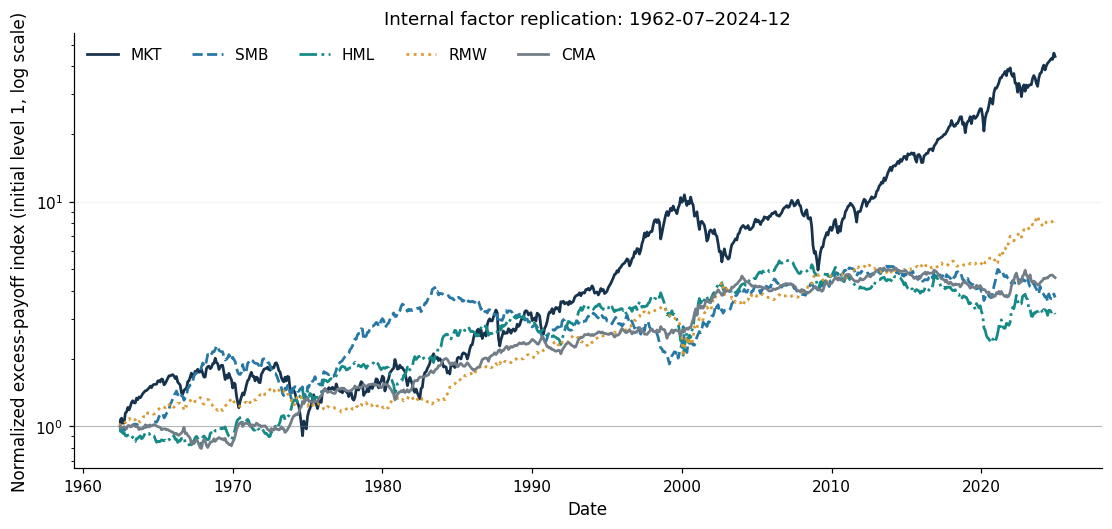

In [13]:
assert (empirical_factors > -1).all().all(), 'Positive index plotting requires payoffs above -100%.'
index_paths = (1+empirical_factors).cumprod()
initial_date = (months[0]-1).to_timestamp(how='end').normalize()
index_paths = pd.concat([pd.DataFrame(1., index=[initial_date], columns=factor_names), index_paths])
# Independent scalar recurrence checks every plotted observation, including initial capital.
for k, name in enumerate(factor_names):
    manual_path = [1.]
    for payoff in X[:,k]:
        manual_path.append(manual_path[-1]*(1+float(payoff)))
    np.testing.assert_allclose(index_paths[name], manual_path, rtol=1e-12, atol=1e-12)
fig, ax = plt.subplots(figsize=(10, 4.7), layout='constrained')
for name, color, line in zip(factor_names, [NAVY, BLUE, GREEN, ORANGE, GRAY], ['-', '--', '-.', ':', '-']):
    ax.plot(index_paths.index, index_paths[name], color=color, linestyle=line, label=name)
ax.set_yscale('log')
ax.axhline(1, color=GRAY, lw=.7, alpha=.5)
ax.set(xlabel='Date', ylabel='Normalized excess-payoff index (initial level 1, log scale)',
       title=f'Internal factor replication: {months[0]}–{months[-1]}')
ax.legend(ncol=5, loc='upper left', frameon=False)
ax.grid(axis='y', alpha=.15, which='major')
plt.show()


*Empirical prepared replication, common monthly sample.* Each series starts at one immediately before the first included month. The logarithmic vertical axis compares proportional changes. The saved market path ends substantially above the characteristic-factor paths, while the characteristic factors show different periods of gains and losses. Their cumulative ranking is not a ranking of their contribution to a diversified portfolio.

These outcomes describe historical positions, not guaranteed premiums. A positive sample mean can coexist with prolonged losses, overlapping exposures and substantial implementation costs. [04](04_time_series_factor_regressions.ipynb) asks the next investment question: how much of a factor’s payoff is explained by an existing benchmark, and what abnormal mean remains?


## References
- Fama, E. F., and French, K. R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3–56. [DOI](https://doi.org/10.1016/0304-405X(93)90023-5).
- Fama, E. F., and French, K. R. (2015). A five-factor asset pricing model. *Journal of Financial Economics*, 116(1), 1–22. [DOI](https://doi.org/10.1016/j.jfineco.2014.10.010).
- Kenneth French, [five-factor construction documentation](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_5_factors_2x3.html).
